# Optimal Trade Execution Under Changing Liquidity

**Group 5:** Ahmad Mohammad, Luciano Handal, Robert Scott

ADSP 32020 Reinforcement Learning · Autumn 2026 · Professor Francisco Azeredo · End-quarter project

**The question.** A trader must buy 10 lots within five periods. Trading is cheaper when the market is liquid, and liquidity switches at random between a low and a high regime. Does a policy that adapts its trade sizes to the regime cost less than splitting the order equally (TWAP)?

**The approach.** We write the problem as a finite Markov decision process (MDP), solve it exactly with value iteration, and compare the computed policy with two baselines on the same 10,000 simulated liquidity paths.

**The answer.** Not in the base case of our proposal. With high liquidity at twice the low level, the optimal policy buys 2 lots in every period on every liquidity path, exactly like TWAP, so the cost reduction is 0%. The policy itself does depend on liquidity, but only in states that a 10-lot order never reaches. In our sensitivity comparison adapting pays at a liquidity ratio of 4, where the expected cost is 4.95% lower than with TWAP.

| Section | Content |
|---|---|
| 1 | Problem description |
| 2 | Environment description |
| 3 | Solution method |
| 4 | Results and policy analysis |
| 5 | Agent demonstration |
| 6 | Requirements |
| 7 | Conclusions |

In [1]:
from dataclasses import dataclass, replace
from importlib.metadata import version
from itertools import product
from pathlib import Path
import math
import platform

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap

SEED = 32020           # seed for every random draw in this notebook (the course number)
N_PATHS = 10_000       # simulated liquidity paths
TOL = 1e-8             # stopping tolerance of value iteration
LOW, HIGH = 0, 1       # index of the liquidity regime
REGIME = ("low", "high")

DATA, RESULTS = Path("data"), Path("results")
FIGURES = RESULTS / "figures"
for folder in (DATA, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

In [2]:
# One color palette for every figure, chosen to stay distinguishable under color blindness.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GRAY, INK, MUTED, WASH = "#c3c2b7", "#0b0b0b", "#52514e", "#f0efec"
POLICY_COLOR = {"optimal": BLUE, "TWAP": ORANGE, "buy all at once": AQUA}
# periods remaining 1..5, light to dark
TAU_COLOR = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]
LOTS_CMAP = LinearSegmentedColormap.from_list(
    "lots", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])     # more lots, darker blue

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRAY, "axes.labelcolor": MUTED,
    "axes.titlesize": 10.5, "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
    "lines.linewidth": 2, "lines.markersize": 6.5,
    "lines.markeredgecolor": "white", "lines.markeredgewidth": 1.2,
})


def finish(fig, name):
    """Save a figure under results/figures and show it."""
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")
    plt.show()


def show_table(table, decimals=4):
    """Display a table with a fixed number of decimals."""
    pattern = "{:,." + str(decimals) + "f}"                 # for example "{:,.4f}"
    with pd.option_context("display.float_format", pattern.format):
        display(table)

## 1. Problem description

**A large order moves the price against the trader, so how the order is split over time matters.** Buying all at once pays the full market impact, and spreading the purchases lowers it. The execution problem is to choose the trade in each period so that the whole order is completed by a deadline at the lowest expected cost.

**Our application.** A trader must buy 10 equal lots within five periods. Each trade has a temporary market-impact cost that grows with the square of its size and falls with the liquidity of the market in that period. Liquidity is observed before each trade and switches at random between a low and a high regime. The underlying price is constant, which isolates the effect of liquidity. We ask whether a policy that reacts to the observed regime costs less than the usual benchmark, the time-weighted average price (TWAP) schedule that buys the same amount in every period.

**Where the problem comes from.**
- **Bertsimas and Lo (1998)** pose execution as a stochastic dynamic program. With a linear price impact and no information the equal split is optimal, and when the trader observes a serially correlated signal the optimal trades react to it. Our Week 5 lab implemented that model and solved it in closed form.
- **Almgren and Chriss (2001)** add the trader's aversion to price risk and separate temporary from permanent impact. Our cost is a purely temporary impact.
- **Almgren (2012)** studies execution when liquidity itself varies at random, which is the question we ask in a much simpler setting.
- **Cheridito and Sepin (2014)** solve a discrete-time execution problem in which volatility and liquidity are both random, and compare the result with the fixed schedules of Bertsimas and Lo and of Almgren and Chriss.
- **Nevmyvaka, Feng and Kearns (2006)** apply reinforcement learning to execution on limit order book data, with the elapsed time and the remaining inventory among the state variables. The same two quantities describe our trader.

**What we change relative to the lab.** We keep the setting: a buy order, a deadline, the equal split and the all-at-once purchase as benchmarks, and 10,000 simulated runs shared by all strategies. We change the model in three ways: trades are whole lots, the cost is a temporary quadratic impact, and what the trader observes is a two-state liquidity regime. With whole lots the problem is a finite MDP with 110 states, small enough to solve exactly with value iteration.

Full citations are in the References section at the end.

## 2. Environment description

**The environment is a model that we specify in full; nothing is estimated from data.** It is the MDP of our proposal.

| Element | Definition |
|---|---|
| State | $(\tau, q, l)$: periods remaining $\tau \in \lbrace 1, \dots, 5 \rbrace$, lots remaining $q \in \lbrace 0, \dots, 10 \rbrace$, liquidity regime $l \in \lbrace \text{low}, \text{high} \rbrace$ with liquidity levels $L_{\text{low}} = 1$ and $L_{\text{high}} = 2$ |
| Start | $\tau = 5$, $q = 10$, regime low or high with probability $0.5$ each |
| Action | $a \in \lbrace 0, 1, \dots, q \rbrace$, the lots bought now; in the last period ($\tau = 1$) the only legal action is $a = q$ |
| Reward | $r = -a^2 / L_l$, minus the temporary market-impact cost, in normalized cost units |
| Transition | $q' = q - a$ and $\tau' = \tau - 1$; the regime stays the same with probability $0.8$ and switches with probability $0.2$, whatever the trade |
| Terminal condition | the episode ends when $q = 0$, which the forced final trade guarantees by the end of period 5; the terminal value is $0$ |

Within a period the order of events is:

1. the trader observes the state $(\tau, q, l)$;
2. the trader buys $a$ lots and pays $a^2 / L_l$ at the liquidity just observed;
3. the regime moves to its value for the next period.

There are five trades and four regime moves. The state space has $5 \times 11 \times 2 = 110$ states, and the regime is the only source of randomness.

The next cell holds the parameters and the three functions that define the model: the regime transition matrix, the cost of a trade and the set of legal trades. Everything else in the notebook uses these three functions, so the model is defined in one place.

In [3]:
@dataclass(frozen=True)
class ExecutionParams:
    """Everything that defines one version of the problem."""
    n_lots: int = 10                 # lots to buy
    n_periods: int = 5               # trading periods
    liquidity: tuple = (1.0, 2.0)    # liquidity L in the low and in the high regime
    persistence: float = 0.8         # probability that the regime is the same next period


BASE = ExecutionParams()             # the base case of our proposal


def liquidity_matrix(params):
    """Transition matrix of the regime: M[l, l'] = P(next regime is l' | regime is l)."""
    p = params.persistence
    return np.array([[p, 1 - p], [1 - p, p]])


def trade_cost(a, l, params):
    """Cost of buying a lots in regime l: a^2 / L_l. The reward is minus this cost."""
    return a ** 2 / np.asarray(params.liquidity)[l]


def legal_actions(tau, q):
    """Trades allowed with tau periods and q lots left: 0..q, or exactly q in the last period."""
    return np.array([q]) if tau == 1 else np.arange(q + 1)


print("regime transition matrix (rows: low, high now; columns: low, high next):")
print(liquidity_matrix(BASE))
print("cost of buying 2 lots: low", trade_cost(2, LOW, BASE), "| high", trade_cost(2, HIGH, BASE))
print("legal trades with 3 lots left: 4 periods to go", legal_actions(4, 3),
      "| last period", legal_actions(1, 3))

regime transition matrix (rows: low, high now; columns: low, high next):
[[0.8 0.2]
 [0.2 0.8]]
cost of buying 2 lots: low 4.0 | high 2.0
legal trades with 3 lots left: 4 periods to go [0 1 2 3] | last period [3]


### 2.1 The Gymnasium environment

**The same model as a Gymnasium environment**, with the `reset` and `step` interface used throughout the course.

- **Observation:** the array `[tau, q, l]`, in the space `MultiDiscrete([6, 11, 2])`.
- **Action:** the number of lots to buy, in the space `Discrete(11)`. `info["action_mask"]` marks the trades that are legal in the current state.
- **Illegal trades** raise an error; they are not silently corrected.
- **Randomness:** `reset(seed=...)` seeds the regime draws. `reset(options={"liquidity_path": ...})` replays a given sequence of regimes instead, so that different policies can face the same liquidity.

Value iteration does not need this class: it works directly on the model functions above. We use the environment for the demonstration in section 5 and to check the simulator in section 4.3. `rollout` runs one episode with a policy table and returns the log.

In [4]:
class TradeExecutionEnv(gym.Env):
    """Buy n_lots within n_periods. Observation [tau, q, l]; the action is the number of lots to buy now."""

    def __init__(self, params=BASE):
        self.params = params
        self.observation_space = spaces.MultiDiscrete([params.n_periods + 1, params.n_lots + 1, 2])
        self.action_space = spaces.Discrete(params.n_lots + 1)

    def _observation(self):
        return np.array([self.tau, self.q, self.l])

    def _info(self):
        mask = np.zeros(self.params.n_lots + 1, dtype=np.int8)  # 1 marks a legal trade
        if self.q > 0:
            mask[legal_actions(self.tau, self.q)] = 1
        return {"action_mask": mask}

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.path = (options or {}).get("liquidity_path")       # optional pre-set regimes, one per period
        self.tau, self.q = self.params.n_periods, self.params.n_lots
        self.l = int(self.path[0]) if self.path is not None else int(self.np_random.integers(2))
        return self._observation(), self._info()

    def step(self, action):
        action = int(action)
        if self.q == 0:
            raise RuntimeError("the episode is over; call reset()")
        if action not in legal_actions(self.tau, self.q):
            raise ValueError(f"illegal trade {action} with tau={self.tau}, q={self.q}")
        cost = float(trade_cost(action, self.l, self.params))   # paid at the liquidity seen before trading
        self.q -= action
        self.tau -= 1
        terminated = self.q == 0
        if not terminated:                                      # only then does liquidity move
            if self.path is not None:
                self.l = int(self.path[self.params.n_periods - self.tau])
            elif self.np_random.random() >= self.params.persistence:
                self.l = 1 - self.l
        # Written as 0.0 - cost so that buying nothing gives a reward of 0.0, not -0.0.
        reward = 0.0 - cost
        return self._observation(), reward, terminated, False, self._info()


def rollout(env, policy, liquidity_path=None, seed=None):
    """Run one episode with a policy table policy[tau, q, l] and return the step-by-step log."""
    obs, info = env.reset(seed=seed, options={"liquidity_path": liquidity_path})
    log, terminated = [], False
    while not terminated:
        tau, q, l = obs
        obs, reward, terminated, truncated, info = env.step(policy[tau, q, l])
        log.append({"period": env.params.n_periods - tau + 1, "liquidity": REGIME[l], "lots left": q,
                    "trade": policy[tau, q, l], "cost": abs(reward)})
    return pd.DataFrame(log)

In [5]:
env = TradeExecutionEnv(BASE)
check_env(env, skip_render_check=True)           # Gymnasium's own test of the reset/step interface
print("passes Gymnasium's environment checker")
print("observation space:", env.observation_space, "| action space:", env.action_space)

obs, info = env.reset(seed=SEED)
print(f"\nreset: observation [tau, q, l] = {obs} | legal trades {np.flatnonzero(info['action_mask'])}")
for trade in (3, 0, 4, 1, 2):                    # a hand-picked schedule, only to show the mechanics
    obs, reward, terminated, truncated, info = env.step(trade)
    print(f"buy {trade}: reward {reward:5.1f} | observation {obs} | terminated {terminated} | "
          f"legal next {np.flatnonzero(info['action_mask'])}")

env.reset(seed=SEED)
env.step(4)
env.step(4)
try:
    env.step(5)                                  # only 2 lots are left
except ValueError as error:
    print("\nrejected:", error)

passes Gymnasium's environment checker
observation space: MultiDiscrete([ 6 11  2]) | action space: Discrete(11)

reset: observation [tau, q, l] = [ 5 10  0] | legal trades [ 0  1  2  3  4  5  6  7  8  9 10]
buy 3: reward  -9.0 | observation [4 7 0] | terminated False | legal next [0 1 2 3 4 5 6 7]
buy 0: reward   0.0 | observation [3 7 0] | terminated False | legal next [0 1 2 3 4 5 6 7]
buy 4: reward -16.0 | observation [2 3 1] | terminated False | legal next [0 1 2 3]
buy 1: reward  -0.5 | observation [1 2 1] | terminated False | legal next [2]
buy 2: reward  -2.0 | observation [0 0 1] | terminated True | legal next []

rejected: illegal trade 5 with tau=3, q=2


**The run shows the rules of the environment.**

- **The reward is minus the cost at the regime observed before the trade.** Buying 3 lots in low liquidity costs $3^2 / 1 = 9$, and buying 1 lot in high liquidity costs $1^2 / 2 = 0.5$.
- **Liquidity moves after the trade.** Here the regime changed from low to high after the third trade.
- **The last trade is forced.** With one period left the only legal trade is the 2 lots that remain, and the episode ends when nothing is left.
- **An illegal trade is rejected**, here an attempt to buy 5 lots when 2 are left.

**What the model leaves out.** These simplifications are the hard parts of real trade execution:

- **No price process.** The price is constant, so there is no price risk and no reason to trade early other than the deadline.
- **The impact is known, temporary and quadratic.** There is no permanent impact and no order book.
- **Liquidity is observed without error**, has two levels and a known persistence, and does not react to the trader.
- **Costs are in normalized units** and are not calibrated to market data.

They keep the problem small enough to solve exactly and isolate one effect. The conclusions are therefore statements about this model, a point we return to in section 7.

## 3. Solution method

**We solve the MDP with synchronous value iteration.** Let $V(\tau, q, l)$ be the value of the state: minus the lowest expected cost of buying the remaining $q$ lots in $\tau$ periods, starting in regime $l$. It satisfies the Bellman equation

$$V(\tau, q, l) = \max_{a \in A(\tau, q)} \Big[ -\frac{a^2}{L_l} + \sum_{l'} P(l' \mid l) V(\tau - 1, q - a, l') \Big], \qquad V(0, \cdot, \cdot) = 0,$$

where $A(\tau, q) = \lbrace 0, \dots, q \rbrace$ for $\tau > 1$ and $A(1, q) = \lbrace q \rbrace$.

**Implementation.**

- **Tables.** $V$ and the policy are arrays indexed `[tau, q, l]` of shape `(6, 11, 2)`. Layer `tau = 0` holds the terminal value $0$.
- **One sweep.** `bellman_backup` applies the right-hand side of the Bellman equation to every state and reads only the table from the previous sweep, which is what makes the iteration synchronous. The loops run over $\tau$, $q$ and $l$, and the trades $a$ are handled as one vector, so the line that fills `Q` is the Bellman equation.
- **Parameters.** The discount factor is 1, because the horizon is five periods and costs are not discounted. The initial table is zero.
- **Stopping rule.** The iteration stops when the largest absolute change of any state value in a sweep is below $10^{-8}$.
- **Ties.** If two trades have the same value, the policy takes the smaller one (the smallest trade within $10^{-9}$ of the best), so the result does not depend on rounding noise.

**Why it stops although the discount factor is 1.** Every transition lowers $\tau$ by one, so no state is visited twice. The first sweep makes the states with one period left exact, the second those with two periods left, and so on. After five sweeps the table is exact, and the sixth sweep changes nothing.

In [6]:
def bellman_backup(V, params):
    """One synchronous sweep over every state, using only the old table V[tau, q, l].
    Returns the new table and Q[tau, q, l, a], the value of each trade (-inf where the trade is illegal)."""
    T, N = params.n_periods, params.n_lots
    M = liquidity_matrix(params)
    Q = np.full((T + 1, N + 1, 2, N + 1), -np.inf)
    for tau in range(1, T + 1):
        for q in range(N + 1):
            a = legal_actions(tau, q)
            for l in (LOW, HIGH):
                expected_next = V[tau - 1, q - a] @ M[l]              # E[ V(tau - 1, q - a, l') | l ]
                Q[tau, q, l, a] = -trade_cost(a, l, params) + expected_next
    V_new = np.zeros_like(V)
    V_new[1:] = Q[1:].max(axis=-1)
    return V_new, Q


def value_iteration(params, tol=TOL):
    """Synchronous value iteration from V = 0 with discount factor 1.
    Returns V[tau, q, l], the greedy policy[tau, q, l] and the list of tables after every sweep."""
    V = np.zeros((params.n_periods + 1, params.n_lots + 1, 2))
    sweeps = [V]
    while True:
        V, Q = bellman_backup(V, params)
        sweeps.append(V)
        if np.abs(sweeps[-1] - sweeps[-2]).max() < tol:
            break
    near_best = Q[1:] >= V[1:, :, :, None] - 1e-9      # True for every trade within 1e-9 of the best one
    policy = np.zeros(V.shape, dtype=int)
    policy[1:] = np.argmax(near_best, axis=-1)         # position of the first True: the smallest such trade
    return V, policy, sweeps


def expected_cost(V, params):
    """Expected cost of the whole order: minus the start value, averaged over the 50/50 initial regime."""
    return -V[params.n_periods, params.n_lots].mean()


V, policy, sweeps = value_iteration(BASE)
changes = [np.abs(new - old).max() for old, new in zip(sweeps, sweeps[1:])]
print(f"value iteration stopped after {len(changes)} sweeps")
print("largest value change in each sweep:", np.round(changes, 4))
print(f"value at the start: low {V[5, 10, LOW]:.4f} | high {V[5, 10, HIGH]:.4f}")
print(f"expected cost of the order under the computed policy: {expected_cost(V, BASE):.4f}")

value iteration stopped after 6 sweeps
largest value change in each sweep: [100.      47.5     30.4     22.216   17.3056   0.    ]
value at the start: low -17.3056 | high -12.6944
expected cost of the order under the computed policy: 15.0000


## 4. Results and policy analysis

### 4.1 Convergence of value iteration

The left panel shows the quantity behind the stopping rule, the largest change in $V$ in each sweep. The right panel and the table follow one family of states across the sweeps: 10 lots in low liquidity, for each number of periods remaining.

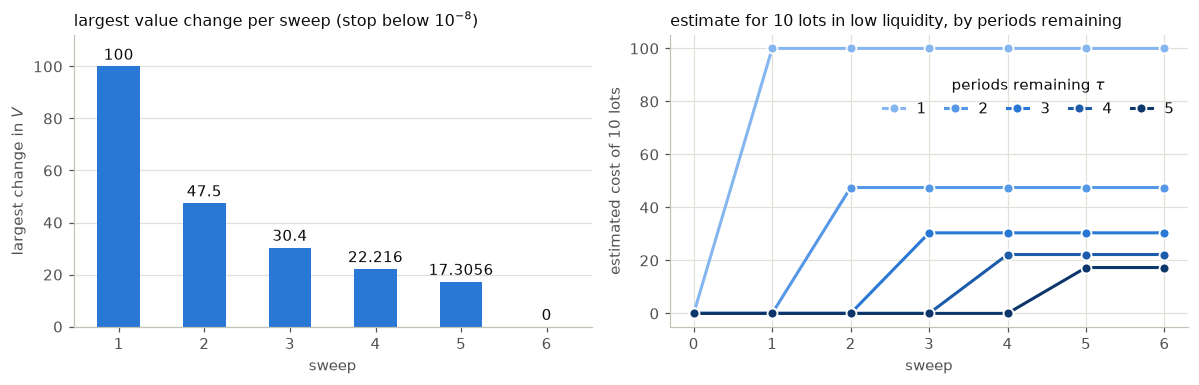

,tau = 1,tau = 2,tau = 3,tau = 4,tau = 5
after sweep,,,,,
0,0.0000,0.0000,0.0000,0.0000,0.0000
1,100.0000,0.0000,0.0000,0.0000,0.0000
2,100.0000,47.5000,0.0000,0.0000,0.0000
3,100.0000,47.5000,30.4000,0.0000,0.0000
4,100.0000,47.5000,30.4000,22.2160,0.0000
5,100.0000,47.5000,30.4000,22.2160,17.3056
6,100.0000,47.5000,30.4000,22.2160,17.3056


In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))

sweep_numbers = np.arange(1, len(changes) + 1)
bars = left.bar(sweep_numbers, changes, width=0.5, color=BLUE)
left.bar_label(bars, labels=[f"{change:g}" for change in changes], padding=2)
left.set(xlabel="sweep", ylabel="largest change in $V$", ylim=(0, 112),
         title=r"largest value change per sweep (stop below $10^{-8}$)")
left.grid(axis="x", visible=False)

for tau in range(1, 6):
    right.plot(range(len(sweeps)), [abs(table[tau, 10, LOW]) for table in sweeps], marker="o",
               color=TAU_COLOR[tau - 1], label=str(tau))
right.set(xlabel="sweep", ylabel="estimated cost of 10 lots",
          title="estimate for 10 lots in low liquidity, by periods remaining")
right.legend(title=r"periods remaining $\tau$", ncol=5, loc="upper right", bbox_to_anchor=(1, 0.9),
             columnspacing=1.2, handlelength=1.4)
finish(fig, "convergence")

show_table(pd.DataFrame([np.abs(table[1:, 10, LOW]) for table in sweeps],
                        index=pd.Index(range(len(sweeps)), name="after sweep"),
                        columns=[f"tau = {tau}" for tau in range(1, 6)]))

**Value iteration converges in exactly six sweeps, one period per sweep.** The largest change is 100, 47.5, 30.4, 22.216 and 17.3056 in sweeps 1 to 5 and exactly 0 in sweep 6, which is below the tolerance of $10^{-8}$. The values at the start are $-17.3056$ in low liquidity and $-12.6944$ in high liquidity, an expected cost of 15 for the order.

- **Each sweep settles one layer.** The right panel and the table follow the state with 10 lots in low liquidity. Its estimate with $\tau$ periods left is 0 until sweep $\tau$, takes its final value in sweep $\tau$ and never changes again.
- **The changes are not a shrinking error.** The change in sweep $k$ is the cost of the most expensive state settled in that sweep, 10 lots with $k$ periods left in low liquidity. It falls from sweep to sweep because more periods allow a finer split, not because an approximation improves.
- **The sixth sweep only confirms.** With time in the state, value iteration is backward induction spread over six sweeps, so the stopping rule is met exactly.

### 4.2 The computed policy and its value

The two grids show the computed policy, one grid per liquidity regime. Each cell is one state, and the number in it is the lots to buy in that state.

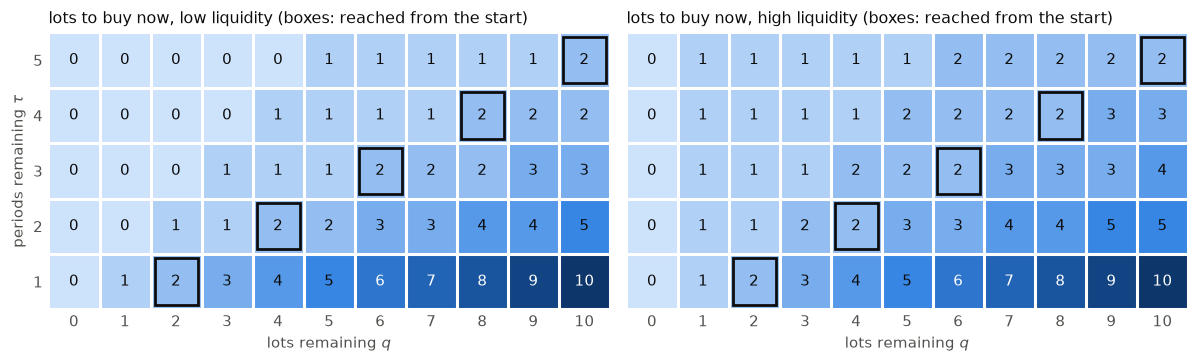

low liquidity:  the policy buys floor(q / tau) in every state: True
high liquidity: the policy buys ceil(q / tau) in every state:  True
states where the two regimes trade differently: 28 of 55
states reached from the start (tau, q): [(5, 10), (4, 8), (3, 6), (2, 4), (1, 2)]


In [8]:
def reached_states(policy, params):
    """States [tau, q, l] visited from the start under the policy, over every possible liquidity path."""
    reached = np.zeros(policy.shape, dtype=bool)
    for path in product((LOW, HIGH), repeat=params.n_periods):
        q = params.n_lots
        for t, l in enumerate(path):
            if q == 0:
                break
            tau = params.n_periods - t
            reached[tau, q, l] = True
            q -= policy[tau, q, l]
    return reached


def draw_grid(ax, table, title, vmax, outline=None):
    """Colored grid of lots, one cell per (lots remaining, periods remaining).
    Cells with a box are the states reached from the start."""
    n_tau, n_q = table.shape[0] - 1, table.shape[1]
    ax.imshow(table[1:], cmap=LOTS_CMAP, vmin=0, vmax=vmax, origin="lower", aspect="auto",
              extent=(-0.5, n_q - 0.5, 0.5, n_tau + 0.5))
    for tau, q in product(range(1, n_tau + 1), range(n_q)):
        text_color = "white" if table[tau, q] > vmax / 2 else INK
        ax.text(q, tau, table[tau, q], ha="center", va="center", color=text_color)
        if outline is not None and outline[tau, q]:
            box = plt.Rectangle((q - 0.42, tau - 0.42), 0.84, 0.84, fill=False,
                                edgecolor=INK, linewidth=1.8)
            ax.add_patch(box)
    ax.set(xticks=range(n_q), yticks=range(1, n_tau + 1), title=title, xlabel="lots remaining $q$")
    ax.set_xticks(np.arange(-0.5, n_q), minor=True)
    ax.set_yticks(np.arange(0.5, n_tau + 1), minor=True)
    ax.grid(False)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="both", length=0)
    ax.spines[:].set_visible(False)


reached = reached_states(policy, BASE)
reached_pairs = [(tau, q) for tau in range(5, 0, -1) for q in range(10, -1, -1) if reached[tau, q].any()]
assert reached_pairs == [(5, 10), (4, 8), (3, 6), (2, 4), (1, 2)]

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for l, ax in zip((LOW, HIGH), axs):
    title = f"lots to buy now, {REGIME[l]} liquidity (boxes: reached from the start)"
    draw_grid(ax, policy[:, :, l], title,
              vmax=BASE.n_lots, outline=reached[:, :, l])
axs[0].set_ylabel(r"periods remaining $\tau$")
finish(fig, "policy")

tau_column, q_row = np.arange(1, 6)[:, None], np.arange(11)[None, :]
print("low liquidity:  the policy buys floor(q / tau) in every state:",
      np.array_equal(policy[1:, :, LOW], np.floor(q_row / tau_column)))
print("high liquidity: the policy buys ceil(q / tau) in every state: ",
      np.array_equal(policy[1:, :, HIGH], np.ceil(q_row / tau_column)))
print("states where the two regimes trade differently:",
      int((policy[1:, :, LOW] != policy[1:, :, HIGH]).sum()), "of", policy[1:, :, LOW].size)
print("states reached from the start (tau, q):", reached_pairs)

**From the start, the computed policy buys 2 lots in every period, whatever the liquidity.** The boxed cells are the states reached from the start: 10, 8, 6, 4 and 2 lots with 5, 4, 3, 2 and 1 periods left. In each of them both regimes prescribe 2 lots.

- **The policy does adapt to liquidity.** It buys $\lfloor q/\tau \rfloor$ lots in low liquidity and $\lceil q/\tau \rceil$ lots in high liquidity: it spreads the remaining lots evenly, rounding down when trading is expensive and up when it is cheap. The two regimes prescribe different trades in 28 of the 55 combinations of $\tau$ and $q$.
- **The adaptation never comes into play.** The two roundings differ only when $q$ is not a multiple of $\tau$. Starting from 10 lots and 5 periods, buying 2 lots per period keeps $q$ equal to $2\tau$, so the order never reaches a state where the regimes disagree.
- **Bottom row.** With one period left the remaining lots must be bought, so the trade equals $q$ in both regimes.

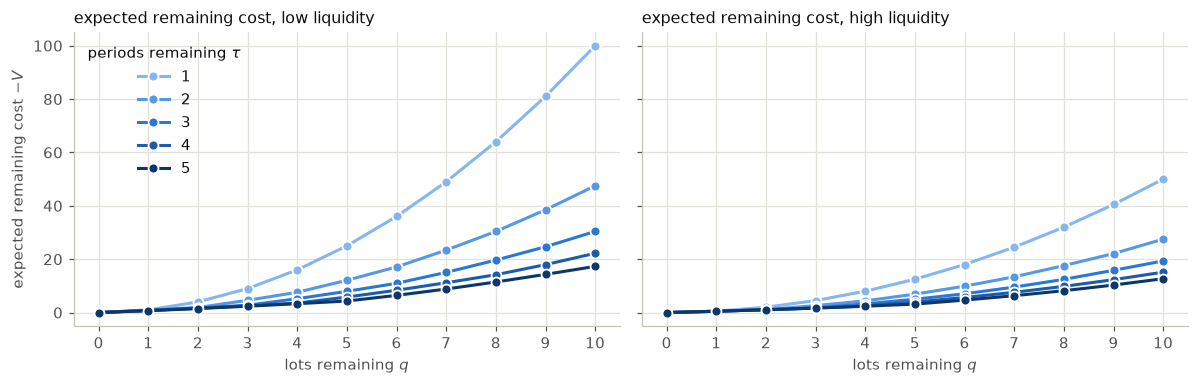

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for l, ax in zip((LOW, HIGH), axs):
    for tau in range(1, 6):
        ax.plot(range(11), -V[tau, :, l], marker="o", color=TAU_COLOR[tau - 1], label=str(tau))
    ax.set(xlabel="lots remaining $q$", xticks=range(11),
           title=f"expected remaining cost, {REGIME[l]} liquidity")
axs[0].set_ylabel("expected remaining cost $-V$")
axs[0].legend(title=r"periods remaining $\tau$", loc="upper left")
finish(fig, "value_function")

**The expected remaining cost is convex in the lots left and falls with the time left.** With one period left it is $q^2 / L$: 100 for 10 lots in low liquidity and 50 in high liquidity. Each extra period allows a finer split and lowers the cost, down to 17.31 (low) and 12.69 (high) for 10 lots with five periods. The current regime matters less with a longer horizon, because later trades are made at whatever liquidity prevails then.

### 4.3 Comparison with the baselines

**Baselines.** TWAP buys the same amount in every period, here 2 lots; in a general state it buys $\lceil q / \tau \rceil$ lots. The second baseline buys all 10 lots in the first period.

**Evaluation.** Every policy is evaluated in two ways: exactly, with `evaluate_policy`, and on the same 10,000 simulated liquidity paths. `evaluate_policy` is the Bellman recursion of section 3 applied to a fixed policy, so it has no maximum. The paths are drawn once from a fixed seed and saved to `data/liquidity_paths.csv`, the raw data of this project.

In [10]:
def twap_policy(params):
    """Equal split: buy ceil(q / tau) lots now, whatever the liquidity."""
    T, N = params.n_periods, params.n_lots
    policy = np.zeros((T + 1, N + 1, 2), dtype=int)
    for tau in range(1, T + 1):
        for q in range(N + 1):
            policy[tau, q, :] = math.ceil(q / tau)
    return policy


def immediate_policy(params):
    """Buy everything that is left at once."""
    T, N = params.n_periods, params.n_lots
    policy = np.zeros((T + 1, N + 1, 2), dtype=int)
    for q in range(N + 1):
        policy[1:, q, :] = q
    return policy


def evaluate_policy(policy, params):
    """Exact value of a fixed policy[tau, q, l]: the Bellman recursion without the max."""
    T, N = params.n_periods, params.n_lots
    M = liquidity_matrix(params)
    V = np.zeros((T + 1, N + 1, 2))
    for tau in range(1, T + 1):
        for q in range(N + 1):
            for l in (LOW, HIGH):
                a = policy[tau, q, l]
                V[tau, q, l] = -trade_cost(a, l, params) + V[tau - 1, q - a] @ M[l]
    return V


def simulate_liquidity_paths(params, n_paths=N_PATHS, seed=SEED):
    """Regime index (0 = low, 1 = high) for every path and period, shape (n_paths, n_periods)."""
    rng = np.random.default_rng(seed)
    paths = np.zeros((n_paths, params.n_periods), dtype=int)
    paths[:, 0] = rng.integers(2, size=n_paths)                       # initial regime: 50/50
    for t in range(1, params.n_periods):
        stay = rng.random(n_paths) < params.persistence
        paths[:, t] = np.where(stay, paths[:, t - 1], 1 - paths[:, t - 1])
    return paths


def run_policy(policy, paths, params):
    """Total cost of a policy on every liquidity path, and its trades (both vectorized over the paths)."""
    n_paths, T = paths.shape
    q = np.full(n_paths, params.n_lots)
    trades = np.zeros((n_paths, T), dtype=int)
    cost = np.zeros(n_paths)
    for t in range(T):
        trades[:, t] = policy[T - t, q, paths[:, t]]
        cost += trade_cost(trades[:, t], paths[:, t], params)
        q = q - trades[:, t]
    assert (q == 0).all()                                             # every policy completes the order
    return cost, trades

In [11]:
def solve_and_simulate(params, paths):
    """Solve one version of the problem and run the optimal policy and both baselines on the same paths."""
    V, optimal, _ = value_iteration(params)
    policies = {"optimal": optimal, "TWAP": twap_policy(params),
                "buy all at once": immediate_policy(params)}
    costs = {name: run_policy(policy, paths, params)[0] for name, policy in policies.items()}
    return V, policies, costs


def cost_table(policies, costs, params):
    """Exact expected cost next to the simulated mean, its standard error and the spread across paths."""
    rows = {}
    for name, policy in policies.items():
        c = costs[name]
        rows[name] = {"exact expected cost": expected_cost(evaluate_policy(policy, params), params),
                      "simulated mean": c.mean(), "std. error": c.std(ddof=1) / np.sqrt(len(c)),
                      "std. dev.": c.std(ddof=1), "lowest": c.min(), "highest": c.max()}
    table = pd.DataFrame(rows).T
    twap_exact = table.loc["TWAP", "exact expected cost"]
    table.insert(1, "exact reduction vs TWAP (%)", 100 * (1 - table["exact expected cost"] / twap_exact))
    return table.rename_axis("policy")


def versus_twap(costs):
    """Saving of each policy relative to TWAP, path by path: every policy faces the same liquidity paths."""
    rows = {}
    for name, c in costs.items():
        saving = costs["TWAP"] - c
        rows[name] = {"simulated reduction vs TWAP (%)": 100 * saving.mean() / costs["TWAP"].mean(),
                      "mean saving per path": saving.mean(),
                      "std. error": saving.std(ddof=1) / np.sqrt(len(saving)),
                      "share of paths cheaper": (saving > 1e-9).mean(),
                      "equal": (np.abs(saving) <= 1e-9).mean(),
                      "more expensive": (saving < -1e-9).mean()}
    return pd.DataFrame(rows).T.drop(index="TWAP").rename_axis("policy")

In [12]:
paths = simulate_liquidity_paths(BASE)
path_table = pd.DataFrame(paths, columns=[f"period_{t}" for t in range(1, 6)])
path_table.to_csv(DATA / "liquidity_paths.csv", index=False, lineterminator="\n")
print("simulated liquidity paths:", paths.shape, "-> saved to", DATA / "liquidity_paths.csv")
print("share of paths in high liquidity, by period:", paths.mean(axis=0).round(3))
print("share of period-to-period moves where the regime stayed:",
      (paths[:, 1:] == paths[:, :-1]).mean().round(4))

_, policies, costs = solve_and_simulate(BASE, paths)
show_table(cost_table(policies, costs, BASE))
show_table(versus_twap(costs))

simulated liquidity paths: (10000, 5) -> saved to data/liquidity_paths.csv
share of paths in high liquidity, by period: [0.501 0.494 0.494 0.496 0.495]
share of period-to-period moves where the regime stayed: 0.7994


,exact expected cost,exact reduction vs TWAP (%),simulated mean,std. error,std. dev.,lowest,highest
policy,,,,,,,
optimal,15.0000,0.0000,15.0398,0.0361,3.6140,10.0000,20.0000
TWAP,15.0000,0.0000,15.0398,0.0361,3.6140,10.0000,20.0000
buy all at once,75.0000,-400.0000,74.9400,0.2500,25.0012,50.0000,100.0000


,simulated reduction vs TWAP (%),mean saving per path,std. error,share of paths cheaper,equal,more expensive
policy,,,,,,
optimal,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000
buy all at once,-398.2779,-59.9002,0.2288,0.0000,0.0000,1.0000


**On the 10,000 simulated paths the optimal policy and TWAP are identical, and buying all at once costs five times as much.**

- **Optimal versus TWAP.** Both have an exact expected cost of 15.0000 and a simulated mean of 15.0398 (standard error 0.0361). Their costs are equal on all 10,000 paths, so the reduction relative to TWAP is 0.00%.
- **Buy all at once.** Its exact expected cost is 75, and its simulated mean is 74.94 (standard error 0.25). It costs more than TWAP on every path: one trade of 10 lots costs $100 / L$, against $4 / L$ for each of the five 2-lot trades.
- **Exact and simulated agree.** The simulated means are within 1.1 standard errors of the exact expected costs. The simulation adds what the expected cost does not show, the spread across paths: a standard deviation of 3.61 for TWAP and the optimal policy and of 25.00 for buying all at once.
- **Common random numbers.** All policies face the same liquidity paths, so they are compared path by path and the comparison is not blurred by sampling noise.

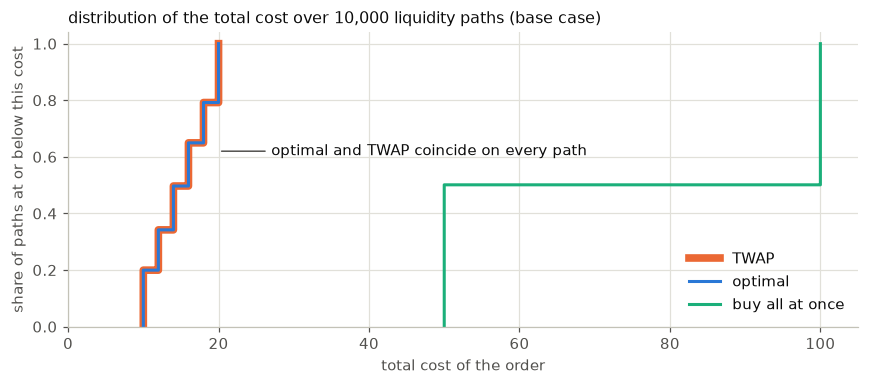

In [13]:
def plot_cost_distribution(ax, costs, names):
    """Share of paths with a total cost at or below each level: one step line per policy."""
    for name in names:                    # ax.ecdf draws the empirical distribution function
        ax.ecdf(costs[name], color=POLICY_COLOR[name], label=name, linewidth=5 if name == "TWAP" else 2)
    ax.set(xlabel="total cost of the order", ylabel="share of paths at or below this cost", ylim=(0, 1.04))


fig, ax = plt.subplots(figsize=(8, 3.6))
plot_cost_distribution(ax, costs, ["TWAP", "optimal", "buy all at once"])
ax.set(title="distribution of the total cost over 10,000 liquidity paths (base case)", xlim=(0, 105))
ax.annotate("optimal and TWAP coincide on every path", xy=(20, 0.62), xytext=(27, 0.62), va="center",
            arrowprops={"arrowstyle": "-", "color": MUTED})
ax.legend(loc="lower right")
finish(fig, "cost_distribution")

**The cost distributions show the same result path by path.** A step line gives the share of paths with a total cost at or below each level. The lines of the optimal policy and TWAP lie on top of each other: their cost runs from 10 (high liquidity in all five periods) to 20 (low in all five) in steps of 2. Buying all at once costs 50 when the first period is liquid and 100 when it is not, each on about half of the paths.

#### Checks

The model appears in three forms in this notebook: the functions used by value iteration, the vectorized simulator and the Gymnasium environment. The next cell checks that they agree. It uses a liquidity ratio of 4, where the optimal trades depend on the regime (section 4.5):

1. evaluating the computed policy exactly gives back the values from value iteration, and neither baseline has a higher value in any state;
2. the simulator and the environment give the same cost on each of the $2^5 = 32$ possible liquidity paths;
3. the simulated mean cost over the 10,000 paths is within 4 standard errors of the exact expected cost.

In [14]:
check = replace(BASE, liquidity=(1.0, 4.0))      # ratio 4, where the optimal trades depend on the regime
V_check, policy_check, _ = value_iteration(check)

# 1. The computed policy earns the values computed for it, and no baseline does better in any state.
assert np.abs(evaluate_policy(policy_check, check) - V_check).max() < 1e-12
for baseline in (twap_policy(check), immediate_policy(check)):
    assert (V_check >= evaluate_policy(baseline, check) - 1e-12).all()

# 2. The simulator and the environment give the same cost on each of the 32 possible liquidity paths.
all_paths = np.array(list(product((LOW, HIGH), repeat=check.n_periods)))
env = TradeExecutionEnv(check)
stepped = [rollout(env, policy_check, path)["cost"].sum() for path in all_paths]
assert np.allclose(run_policy(policy_check, all_paths, check)[0], stepped, rtol=0, atol=1e-9)

# 3. The simulated mean cost is within 4 standard errors of the exact expected cost.
cost_check, _ = run_policy(policy_check, paths, check)
standard_error = cost_check.std(ddof=1) / np.sqrt(len(cost_check))
assert abs(cost_check.mean() - expected_cost(V_check, check)) < 4 * standard_error

print("all checks passed")
print(f"ratio 4: exact expected cost {expected_cost(V_check, check):.4f} | "
      f"simulated mean {cost_check.mean():.4f} (standard error {standard_error:.4f})")

all checks passed
ratio 4: exact expected cost 11.8814 | simulated mean 11.9419 (standard error 0.0599)


### 4.4 Why adapting does not pay in the base case

The policy is free to trade more in liquid periods and less in illiquid ones, yet from the start it does not. To see why, we look at the first trade.

In [15]:
_, Q = bellman_backup(V, BASE)     # Q[5, 10, l, a]: value of buying a lots first, then trading optimally
print("expected cost of the whole order, by first trade")
print(f"start in high liquidity: 2 lots first {-Q[5, 10, HIGH, 2]:.4f} | "
      f"3 lots first {-Q[5, 10, HIGH, 3]:.4f}")
print(f"start in low liquidity:  2 lots first {-Q[5, 10, LOW, 2]:.4f} | "
      f"1 lot first  {-Q[5, 10, LOW, 1]:.4f}")

expected cost of the whole order, by first trade
start in high liquidity: 2 lots first 12.6944 | 3 lots first 12.8088
start in low liquidity:  2 lots first 17.3056 | 1 lot first  17.8296


**In the base case, moving one lot toward the liquid period costs slightly more than it saves.** The cell above takes the start state and changes only the first trade, with optimal trading afterward.

- **High liquidity at the start.** Buying 3 lots instead of 2 costs $9/2 - 4/2 = 2.5$ more now. The expected cost of the whole order still rises, from 12.6944 to 12.8088, so the later saving is only about 2.39. Two lots remain optimal, by a margin of 0.11.
- **Low liquidity at the start.** Buying 1 lot instead of 2 saves $4 - 1 = 3$ now. The expected cost of the whole order rises from 17.3056 to 17.8296, so the later cost is about 3.52 higher.
- **Why the later saving is small.** The cost is convex, so an extra lot now is expensive at the margin. The regime also persists with probability 0.8, so a market that is liquid now will probably still be liquid in the next periods, and there is little to gain from buying ahead.

The next section shows that a larger gap between the two liquidity levels changes this.

### 4.5 Sensitivity to the liquidity ratio

We repeat the comparison for liquidity ratios of 1, 2 and 4 on the same 10,000 paths.

In [16]:
def with_ratio(ratio, params=BASE):
    """The same problem with high liquidity equal to `ratio` times low liquidity (low stays at 1)."""
    return replace(params, liquidity=(1.0, float(ratio)))


solved, exact_rows, simulated_rows = {}, {}, {}
for ratio in (1, 2, 4):
    params = with_ratio(ratio)
    V_r, policies_r, costs_r = solve_and_simulate(params, paths)
    solved[ratio] = (params, V_r, policies_r, costs_r)
    exact_cost = {name: expected_cost(evaluate_policy(p, params), params) for name, p in policies_r.items()}
    assert abs(exact_cost["TWAP"] - (10 + 10 / ratio)) < 1e-9      # five 2-lot trades: 5 * 4 * E[1 / L]
    optimal = policies_r["optimal"]
    exact_rows[ratio] = {**exact_cost,
                         "reduction vs TWAP (%)": 100 * (1 - exact_cost["optimal"] / exact_cost["TWAP"]),
                         "first trade, low": optimal[5, 10, LOW], "first trade, high": optimal[5, 10, HIGH]}
    simulated_rows[ratio] = versus_twap(costs_r).loc["optimal"]

# With constant liquidity (ratio 1) many trades are equally good; the tie rule then takes the smaller one.
policy_1 = solved[1][2]["optimal"]
assert np.array_equal(policy_1[1:, :, LOW], np.floor(q_row / tau_column))
assert np.array_equal(policy_1[1:, :, HIGH], np.floor(q_row / tau_column))

# At ratio 4 the simulated saving agrees with the exact one, in size and in sign.
exact_saving_4 = exact_rows[4]["TWAP"] - exact_rows[4]["optimal"]
assert abs(simulated_rows[4]["mean saving per path"] - exact_saving_4) < 4 * simulated_rows[4]["std. error"]

print("exact expected cost, by liquidity ratio")
exact_table = pd.DataFrame(exact_rows).T.rename_axis("ratio")
show_table(exact_table.astype({"first trade, low": int, "first trade, high": int}))
print("optimal policy against TWAP on the 10,000 simulated paths, by liquidity ratio")
show_table(pd.DataFrame(simulated_rows).T.rename_axis("ratio"))

exact expected cost, by liquidity ratio


,optimal,TWAP,buy all at once,reduction vs TWAP (%),"first trade, low","first trade, high"
ratio,,,,,,
1,20.0000,20.0000,100.0000,0.0000,2,2
2,15.0000,15.0000,75.0000,0.0000,2,2
4,11.8814,12.5000,62.5000,4.9488,1,3


optimal policy against TWAP on the 10,000 simulated paths, by liquidity ratio


,simulated reduction vs TWAP (%),mean saving per path,std. error,share of paths cheaper,equal,more expensive
ratio,,,,,,
1,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000
2,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000
4,4.9191,0.6178,0.0191,0.5924,0.0000,0.4076


ratio 1: reached states where the regimes trade differently: 0, largest difference on a reached state: 0 lots
ratio 2: reached states where the regimes trade differently: 0, largest difference on a reached state: 0 lots
ratio 4: reached states where the regimes trade differently: 8, largest difference on a reached state: 2 lots


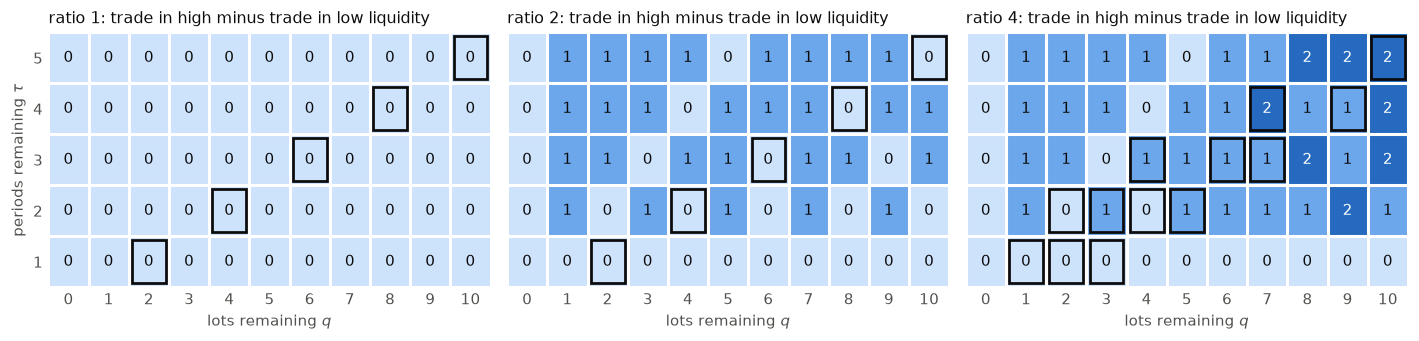

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, (ratio, (params, _, policies_r, _)) in zip(axs, solved.items()):
    optimal = policies_r["optimal"]
    extra = optimal[:, :, HIGH] - optimal[:, :, LOW]
    assert (extra >= 0).all()
    visited = reached_states(optimal, params).any(axis=2)             # (tau, q) reached in either regime
    draw_grid(ax, extra, f"ratio {ratio}: trade in high minus trade in low liquidity",
              vmax=3, outline=visited)
    differ = extra[visited] > 0
    print(f"ratio {ratio}: reached states where the regimes trade differently: {int(differ.sum())}, "
          f"largest difference on a reached state: {int(extra[visited].max())} lots")
axs[0].set_ylabel(r"periods remaining $\tau$")
finish(fig, "ratio_sensitivity")

**The sensitivity analysis of our proposal shows when adapting pays: not at ratios 1 and 2, clearly at ratio 4.** The liquidity ratio is the high level divided by the low level, with the low level fixed at 1. Only the ratio matters for the percentages: multiplying both levels by the same number divides every cost by that number.

- **Ratio 1.** Liquidity is constant, there is nothing to adapt to, and the optimal expected cost equals TWAP's 20.
- **Ratio 2 (base case).** The policy adapts only in states that are never reached, as in section 4.2, and the expected cost equals TWAP's 15.
- **Ratio 4.** The first trade is 3 lots in high liquidity and 1 lot in low liquidity. The expected cost is 11.8814 against 12.5 for TWAP, a reduction of 4.95%. On the simulated paths the reduction is 4.92%, with a mean saving of 0.618 per path (standard error 0.019). The saving is an average: the optimal policy is cheaper than TWAP on 59.2% of the paths and more expensive on 40.8%.
- **The maps** show the trade in high liquidity minus the trade in low liquidity. They are zero everywhere at ratio 1 and zero on every reached state at ratio 2. At ratio 4 the regimes trade differently in 8 reached states, by up to 2 lots.

## 5. Agent demonstration

**The computed policy is saved to `results/optimal_policy.csv` and read back before it acts in the environment**, so this section runs the stored policy, not the arrays still in memory. The file holds the optimal trade and the value of every state for liquidity ratios 1, 2 and 4.

In the first episode below the environment draws the liquidity itself from the seed. In the logs, *lots left* is the number of lots before the trade of that period.

In [18]:
records = []
for ratio, (params, V_r, policies_r, _) in solved.items():
    for tau, q, l in product(range(1, 6), range(11), (LOW, HIGH)):
        records.append({"liquidity_ratio": ratio, "periods_remaining": tau, "lots_remaining": q,
                        "regime": l, "trade": policies_r["optimal"][tau, q, l], "value": V_r[tau, q, l]})
pd.DataFrame(records).to_csv(RESULTS / "optimal_policy.csv", index=False, lineterminator="\n",
                             float_format="%.10g")


def load_policy(ratio):
    """Read the saved optimal policy for one liquidity ratio back into a table policy[tau, q, l]."""
    saved = pd.read_csv(RESULTS / "optimal_policy.csv")
    policy = np.zeros((BASE.n_periods + 1, BASE.n_lots + 1, 2), dtype=int)
    for row in saved[saved["liquidity_ratio"] == ratio].itertuples():
        policy[row.periods_remaining, row.lots_remaining, row.regime] = row.trade
    return policy


agent = load_policy(2)
assert np.array_equal(agent, policy)
print(f"one episode of the base case; the environment draws the liquidity itself (seed {SEED})")
show_table(rollout(TradeExecutionEnv(BASE), agent, seed=SEED).set_index("period"), 2)

one episode of the base case; the environment draws the liquidity itself (seed 32020)


,liquidity,lots left,trade,cost
period,,,,
1,low,10,2,4.00
2,low,8,2,4.00
3,low,6,2,4.00
4,high,4,2,2.00
5,high,2,2,2.00


base case (ratio 2), liquidity changes


,liquidity,lots left,trade,cost,TWAP trade,TWAP cost
period,,,,,,
1,high,10,2,2.00,2,2.00
2,high,8,2,2.00,2,2.00
3,low,6,2,4.00,2,4.00
4,low,4,2,4.00,2,4.00
5,high,2,2,2.00,2,2.00


ratio 4, liquidity changes


,liquidity,lots left,trade,cost,TWAP trade,TWAP cost
period,,,,,,
1,high,10,3,2.25,2,1.00
2,high,7,3,2.25,2,1.00
3,low,4,1,1.00,2,4.00
4,low,3,1,1.00,2,4.00
5,high,2,2,1.00,2,1.00


ratio 4, liquidity stays low


,liquidity,lots left,trade,cost,TWAP trade,TWAP cost
period,,,,,,
1,low,10,1,1.00,2,4.00
2,low,9,2,4.00,2,4.00
3,low,7,2,4.00,2,4.00
4,low,5,2,4.00,2,4.00
5,low,3,3,9.00,2,4.00


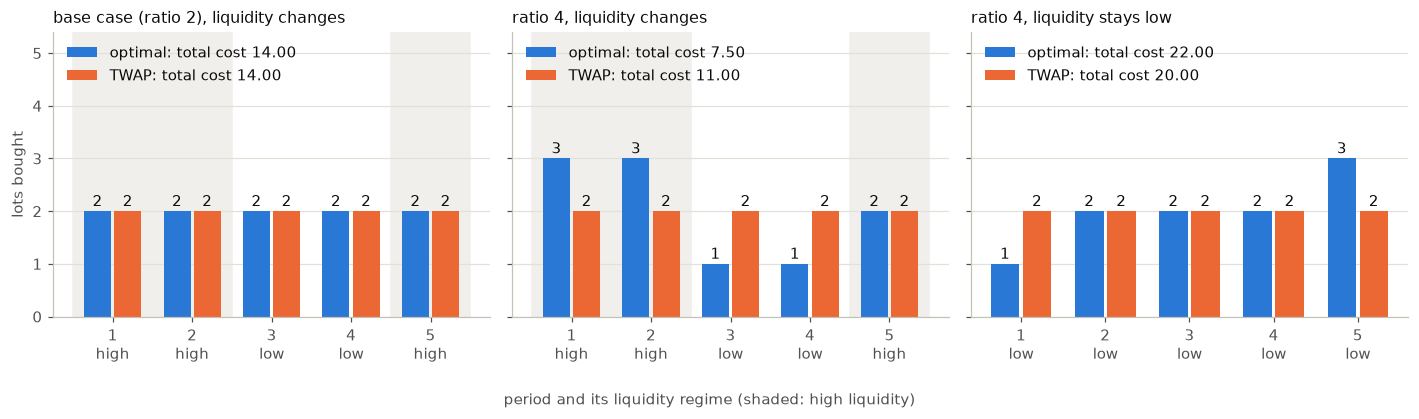

In [19]:
def plot_episode(ax, logs, title):
    """Lots bought per period by each policy on one liquidity path. Shaded periods have high liquidity."""
    periods = np.arange(1, 6)
    regimes = logs["TWAP"]["liquidity"].to_numpy()
    for t in periods[regimes == "high"]:
        ax.axvspan(t - 0.5, t + 0.5, color=WASH, zorder=0)
    for shift, (name, log) in zip((-0.19, 0.19), logs.items()):
        trades = log.set_index("period")["trade"].reindex(periods, fill_value=0)
        bars = ax.bar(periods + shift, trades, width=0.34, color=POLICY_COLOR[name],
                      label=f"{name}: total cost {log['cost'].sum():.2f}")
        ax.bar_label(bars, padding=1)
    tick_labels = [f"{t}\n{r}" for t, r in zip(periods, regimes)]
    ax.set(title=title, xticks=periods, xticklabels=tick_labels, ylim=(0, 5.4))
    ax.grid(axis="x", visible=False)
    ax.legend(loc="upper left")


episodes = [("base case (ratio 2), liquidity changes", 2, [HIGH, HIGH, LOW, LOW, HIGH]),
            ("ratio 4, liquidity changes", 4, [HIGH, HIGH, LOW, LOW, HIGH]),
            ("ratio 4, liquidity stays low", 4, [LOW, LOW, LOW, LOW, LOW])]
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (title, ratio, path) in zip(axs, episodes):
    env = TradeExecutionEnv(with_ratio(ratio))
    logs = {"optimal": rollout(env, load_policy(ratio), path),
            "TWAP": rollout(env, twap_policy(env.params), path)}
    plot_episode(ax, logs, title)
    print(title)
    table = logs["optimal"].set_index("period")
    table["TWAP trade"] = logs["TWAP"]["trade"].to_numpy()
    table["TWAP cost"] = logs["TWAP"]["cost"].to_numpy()
    show_table(table, 2)
axs[0].set_ylabel("lots bought")
fig.supxlabel("period and its liquidity regime (shaded: high liquidity)", fontsize=10, color=MUTED)
finish(fig, "episodes")

**The agent buys the order period by period, and the three episodes of the figure show when it differs from TWAP.** In the first episode above, the environment drew three periods of low liquidity followed by two of high liquidity, and the agent bought 2 lots each time, at a total cost of $3 \times 4 + 2 \times 2 = 16$. In the three episodes of the figure the optimal policy and TWAP face the same liquidity path.

- **Base case, liquidity changes** (high, high, low, low, high). The agent buys 2 lots in every period, like TWAP, and both pay 14.
- **Ratio 4, liquidity changes** (the same path). The agent buys 3 lots in each of the first two liquid periods, 1 lot in each illiquid period and the last 2 lots when liquidity returns. It pays 7.50 against 11.00 for TWAP.
- **Ratio 4, liquidity stays low.** The agent buys only 1 lot at first, waiting for a liquidity that never comes, and has to buy 3 lots in the last period. It pays 22 against 20 for TWAP. This is one of the paths on which the optimal policy costs more (section 4.5).

## 6. Requirements

In [20]:
print("operating system:", platform.system(), platform.release(), platform.machine())
print("python:", platform.python_version())
for package in ("numpy", "pandas", "matplotlib", "gymnasium", "ipykernel"):
    print(f"{package}: {version(package)}")

operating system: Darwin 27.2.0 arm64
python: 3.12.12
numpy: 2.5.5
pandas: 3.1.1
matplotlib: 3.11.2
gymnasium: 1.4.0
ipykernel: 7.4.0


The cell above lists the libraries the notebook imports and the Jupyter kernel that runs it, with the versions on the machine that produced this run. The repository pins them, together with the tools used to open and export the notebook (JupyterLab and nbconvert), so anyone can reproduce it:

```
git clone https://github.com/ahmedas91/rl-optimal-trade-execution.git
cd rl-optimal-trade-execution
uv sync
uv run jupyter lab optimal_trade_execution.ipynb
```

- **With uv:** `uv sync` creates `.venv` with Python 3.12 and the exact package versions recorded in `uv.lock`.
- **Without uv:** create a Python 3.12 environment and run `pip install -r requirements.txt`.
- **Running it:** run all cells from the top. The notebook needs no data download and no GPU, and it finishes in well under a minute. It rewrites `data/liquidity_paths.csv`, `results/optimal_policy.csv` and the figures in `results/figures/`.
- **The environment is never rendered**, so no display window opens.

## 7. Conclusions

**Key findings**

1. **In the base case of our proposal, adapting to liquidity does not reduce the execution cost.** From the start state the optimal policy trades exactly like TWAP: an expected cost of 15 for both, the same cost on every simulated path and a reduction of 0%.
2. **The optimal policy still depends on liquidity.** It rounds the equal split down in low liquidity and up in high liquidity. A 10-lot order over five periods never reaches a state where the two differ.
3. **Adapting pays when the two liquidity levels are far enough apart.** In the sensitivity comparison the reduction relative to TWAP is 0% at ratios 1 and 2 and 4.95% at ratio 4 (4.92% on the simulated paths).
4. **A lower expected cost is not a lower cost on every path.** At ratio 4 the optimal policy costs more than TWAP on 40.8% of the simulated paths, for example when liquidity stays low in all five periods (section 5).
5. **Splitting the order matters far more than adapting it.** Buying all at once has an expected cost of 75 against 15 for TWAP, while the optimal policy improved on TWAP by 0% in the base case and by 4.95% at ratio 4. This echoes our Week 5 lab, where splitting the order accounted for almost all of the saving and the information for very little.
6. **On this finite-horizon problem, value iteration is backward induction.** It settles one period per sweep and stops after six sweeps with a change of exactly zero.

**Limitations**

- **The results are properties of the model.** The environment has no price risk, a known temporary quadratic impact, a perfectly observed two-state liquidity regime that the trader cannot influence, and costs in normalized units.
- **The method relies on knowing the model.** Value iteration needs the transition probabilities and the cost function. With real market data they would have to be estimated, or the policy learned with a model-free method.
- **Only the liquidity ratio is varied.** The persistence of the regime, the number of periods and the size of a lot stay at their base values.
- **The problem is small.** With 110 states it can be solved exactly. A realistic state (prices, order-book depth, several assets) would not fit in a table.

**Challenges encountered**

*To be written by the group before submission.*

**Lessons learned**

*To be written by the group before submission.*

## References

1. Almgren, R. (2012). Optimal trading with stochastic liquidity and volatility. *SIAM Journal on Financial Mathematics*, 3(1), 163–181. https://doi.org/10.1137/090763470
2. Almgren, R., & Chriss, N. (2001). Optimal execution of portfolio transactions. *The Journal of Risk*, 3(2), 5–39. https://doi.org/10.21314/JOR.2001.041
3. Bertsimas, D., & Lo, A. W. (1998). Optimal control of execution costs. *Journal of Financial Markets*, 1(1), 1–50. https://doi.org/10.1016/S1386-4181(97)00012-8
4. Cheridito, P., & Sepin, T. (2014). Optimal trade execution under stochastic volatility and liquidity. *Applied Mathematical Finance*, 21(4), 342–362. https://doi.org/10.1080/1350486X.2014.881005
5. Nevmyvaka, Y., Feng, Y., & Kearns, M. (2006). Reinforcement learning for optimized trade execution. *Proceedings of the 23rd International Conference on Machine Learning*, 673–680. https://doi.org/10.1145/1143844.1143929
6. Puterman, M. L. (1994). *Markov Decision Processes: Discrete Stochastic Dynamic Programming*. Wiley. https://doi.org/10.1002/9780470316887 (Chapter 4, Finite-Horizon Markov Decision Processes.)
7. Sutton, R. S., & Barto, A. G. (2018). *Reinforcement Learning: An Introduction* (2nd ed.). MIT Press. (Section 4.4, Value Iteration.)
8. Towers, M., Kwiatkowski, A., Balis, J., et al. (2025). Gymnasium: A standard interface for reinforcement learning environments. *Advances in Neural Information Processing Systems 38*, 163114–163129. https://doi.org/10.52202/085713-4916

**Code.** All the code is in this notebook and was written for this project. It uses NumPy, pandas, Matplotlib and Gymnasium, and no code from external repositories. Repository of this project: https://github.com/ahmedas91/rl-optimal-trade-execution

## Use of generative AI

This notebook was drafted with Claude (Anthropic, Claude Fable 5.2, through Claude Code) on November 17 and 18, 2026, working from the group's project proposal. The assistant wrote the code, the checks, the figures, a first draft of the commentary and the repository's README.

**What the group did**

*To be completed by the group before submission: what was reviewed, changed and verified.*